# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhang 2021's RCC malignant manifold is **non-branching**: the developmental signatures collapse
onto a **single dominant axis** — posterior-somitogenesis (pSom)-high at one pole opposed to a
neural-crest (Crest)-high terminus — rather than a hub radiating to discrete subtypes with
cross-repression. A PPT *tree* over this low-aspect cloud throws spurious forks (the executed cell
below reports the count), while an ElPiGraph **principal curve** (non-branching by construction) fits
a fold-free monotone backbone. The curve is fit on the *joint* embedding (**not** a re-embedding,
which fabricates folds in an anisotropic cloud — the Kürten §4 / Chen failure mode).

**Scope decision (derived).** Proliferation is flat and cycling cells are a distributed 3% minority
(01), so there is **no cycling compartment** to scope out; the whole malignant manifold is one
developmental cloud and is kept intact. The root is derived from the signatures (pSom-high /
Crest-low tip — Crest is developmentally *late*, the Kürten root lesson); pseudotime flows to the
neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the processed manifold and score developmental modules
All cells stay on their original joint-embedding coordinates — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool and graph-smoothed (3-step kNN averaging) to read geography rather than 10x per-cell
dropout. The UMAP aspect ratio confirms a low-aspect (~round) cloud.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); u, s, vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast', 'GSE229103':'pSom', 'rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 11218 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.25
Gast: 74/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present
raw module means (honest readout): {'Gast': -0.0336, 'pSom': 0.0846, 'Crest': -0.0596}


### Signature geography — one developmental axis
The dominant developmental contrast is **posterior-somitogenesis body vs neural-crest terminus**:
Crest is strongly spatially anti-correlated with pSom (r ≈ −0.9), and pSom and Gast oppose each
other (r ≈ −0.6). This is a single-axis geography (a pSom → Crest gradient), not Puram's
Gast↔pSom competitive-arm hub. There is no cycling compartment (01), so no lobe scoping; the whole
manifold is the trajectory object.

In [ ]:
print('smoothed spatial correlations on the whole manifold:')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','pSom_sm'), ('Crest_sm','Gast_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('proliferation per low-res lobe (flat -> not a proliferative axis):',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.61
  Crest_sm vs pSom_sm: r = -0.91
  Crest_sm vs Gast_sm: r = +0.39
proliferation per low-res lobe (flat -> not a proliferative axis): {'0': 0.001, '1': -0.008}


### Fit the principal curve (ElPiGraph) — and show why not a tree
`Nodes / epg_lambda / epg_mu` give a fold-free monotone backbone: a node **self-approach ratio > 1**
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself (the Kürten/Chen fold failure mode). The 2-tip / 0-fork topology
and fold-freeness are **stable across Nodes = 15/20/30**. A PPT *tree* on the same cloud is shown to
throw many spurious forks — confirming the curve, not the tree, is the correct topology.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print(f'PPT tree(200 nodes): {int(((Bt>0).sum(0)==1).sum())} tips, '
      f'{int(((Bt>0).sum(0)>=3).sum())} forks (spurious -> use curve, not tree)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.74
curve N=30: 2 tips, 0 forks | self-approach 2.12
PPT tree(200 nodes): 7 tips, 4 forks (spurious -> use curve, not tree)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.74 (>1 = fold-free)


### Derive the root (data-driven) and infer pseudotime
The origin is the **posterior-somitogenesis (pSom)-high / neural-crest (Crest)-low** tip: pSom is
the strongest, most origin-concentrated developmental module here, and Crest is developmentally
*late*. The root is the curve tip maximising `pSom − Crest` on cells within 3 graph steps; scoring
by `Gast + pSom − Crest` selects the **same** tip (Gast, weaker, does not move it). Pseudotime then
flows to the neural-crest terminus — the developmentally-ordered root read from the signatures, not
a subtype name or a proliferation state.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} '
          f'| pSom-Crest={info[tp][1]-info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][1]-info[tp][2]))
root_alt = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print(f'derived root = tip {root} (pSom-high, Crest-low origin); '
      f'Gast+pSom-Crest scoring gives tip {root_alt} -> {"same tip (pSom drives it)" if root==root_alt else "DIFFERS"}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
for m, lab_ in [('Crest_sm','Neural-crest'), ('pSom_sm','Somitogenesis'), ('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0292 pSom=+0.0827 Crest=-0.0627 | pSom-Crest=+0.1454
tip 2: Gast=-0.0333 pSom=+0.0753 Crest=-0.0530 | pSom-Crest=+0.1283
derived root = tip 0 (pSom-high, Crest-low origin); Gast+pSom-Crest scoring gives tip 0 -> same tip (pSom drives it)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.230 p=7.8e-135
  pSom_sm: rho=-0.280 p=1.0e-200
  Crest_sm: rho=+0.479 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.72
Somitogenesis-high decile mean pseudotime = 0.41
Gastrulation-high decile mean pseudotime = 0.39


### Fold check — draw the fitted curve edges over pseudotime
The recurring failure mode (Kürten §4, Chen attempt-6) is a folded curve certified continuous by a
metric blind to the fold. We render the fitted curve **edges** directly on the embedding, coloured
by pseudotime, with the root tip marked: a single monotone arc with no self-crossing is fold-free
(consistent with the self-approach ratio above).

single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)


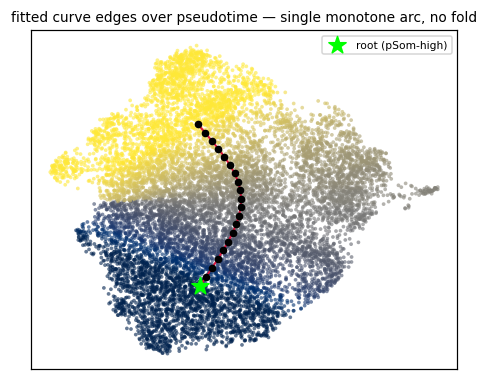

In [ ]:
F = sub.uns['graph']['F'].T; Bc = np.asarray(sub.uns['graph']['B'])
tps2 = np.where((Bc>0).sum(0)==1)[0]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], s=6, c=sub.obs['t'], cmap='cividis', alpha=.6, lw=0)
ii, jj = np.where(np.triu(Bc>0))
for a, b in zip(ii, jj): ax.plot([F[a,0],F[b,0]], [F[a,1],F[b,1]], '-', color='crimson', lw=1.3)
ax.scatter(F[:,0], F[:,1], s=16, c='k', zorder=5)
ax.scatter([F[root,0]], [F[root,1]], s=140, marker='*', c='lime', zorder=6, label='root (pSom-high)')
ax.set_title('fitted curve edges over pseudotime — single monotone arc, no fold', size=9)
ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=7)
plt.show()
print('single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)')

### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal —
was derived **once in 01** (rotation aligning the pSom→Crest module-geography gradient to the
x-axis, pSom-high origin on the left) and stored as `X_umap_lin`. Every UMAP deliverable across
01–04 re-uses these exact coordinates, so orientation is consistent by construction (binding). Here
we **verify** the layout now that pseudotime exists: the correlation of the stored `X_umap_lin`
x-axis with pseudotime must be strongly positive (low pseudotime = developmental origin on the
left).

In [ ]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f} (low pt on left)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.66 (low pt on left)


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis. The
non-serializable ElPiGraph `uns['epg']` entry is reduced to its node positions (the graph itself
lives in `uns['graph']`) so the manifold is h5ad-serializable.

saved manifold.h5ad + manifold.pdf | cells: 11218


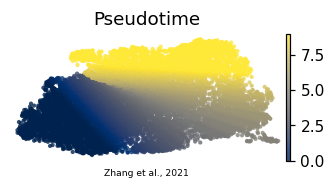

In [ ]:
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf | cells:', sub.n_obs)